# Visualisatie & Storytelling – Eindopdracht deel 1

**Studenten:**
- Kaan Alhan
- John Shoghnani

**Werkversie – opdrachten A, C en E**

Gebruik dit als voorbeeld en controleer alle keuzes. Schrijf de onderbouwingen zelf in eigen woorden en maak voldoende eigen code. De AI-regel geldt voor het volledige gezamenlijke notebook. Opdrachten B, D en F worden door de medestudent toegevoegd.

## Data inladen

In [1]:
# AI-bron: prompt 1 (dataset inladen), prompt 2 (werkversie A, C en E).
import pandas as pd
import matplotlib.pyplot as plt

bos = pd.read_csv("forest_area_cleaned.csv")
temperatuur = pd.read_csv("city_temperature_preprocessed.csv")

## A – Wereldwijde bosontwikkeling (1990–2020)

Vraag: hoe verandert het totale bosoppervlak in de wereld?

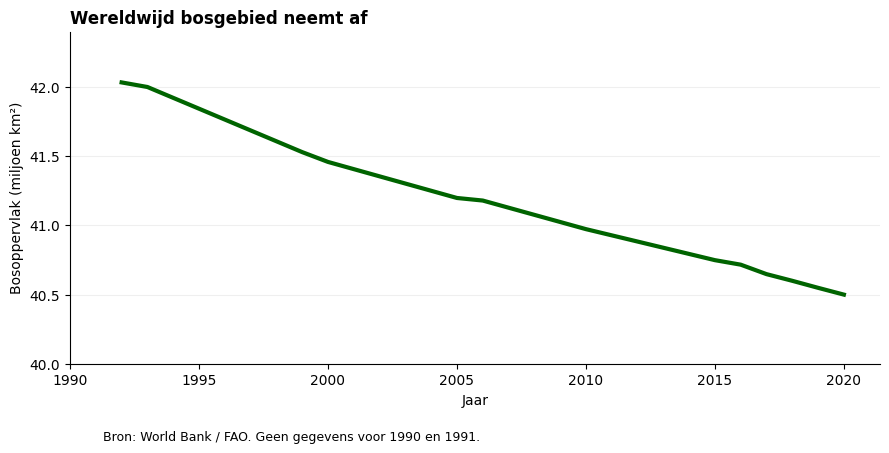

In [2]:
# AI-bron: prompt 2 (werkversie A, C en E).
wereld = bos[bos["area_name"] == "World"]
wereld = wereld[wereld["year"].between(1990, 2020)]

plt.figure(figsize=(9, 4.5))
plt.plot(wereld["year"], wereld["forest_area"] / 1_000_000, color="darkgreen", linewidth=3)
plt.title("Wereldwijd bosgebied neemt af", loc="left", fontweight="bold")
plt.xlabel("Jaar")
plt.ylabel("Bosoppervlak (miljoen km²)")
plt.xticks(range(1990, 2021, 5))
plt.ylim(40, 42.4)
plt.grid(axis="y", alpha=0.2)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.figtext(0.12, 0.01, "Bron: World Bank / FAO. Geen gegevens voor 1990 en 1991.", fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

### Onderbouwing A – zelf formuleren

- **Grafiekkeuze:** lijngrafiek; chronologische gegevens; richting van de verandering zichtbaar; geen losse staven nodig.
- **Context:** circa 42,03 miljoen km² in 1992 en 40,50 miljoen km² in 2020; afname circa 1,53 miljoen km². 1990 en 1991 ontbreken. Welke maatregel zou je aan VN-leiders voorstellen?
- **Clutter:** geen legenda voor één lijn; boven- en rechterrand weg; alleen lichte horizontale hulplijnen; jaartallen om de vijf jaar. Leg uit waarom dat helpt.
- **Visuele focus:** dikke donkergroene lijn tegen rustige achtergrond; duidelijke boodschap in titel; continuïteit (gestalt). De y-as begint niet op nul: leg uit dat dit de trend zichtbaar maakt, zonder de afname groter voor te stellen dan de getallen aangeven.

## B – Bosgebied per inkomensgroep

*Ruimte voor bijdrage medestudent.*

## C – Bosontwikkeling in drie landen en de wereld (2018–2020)

Vraag: hebben alle landen dezelfde ontwikkeling als de wereld?

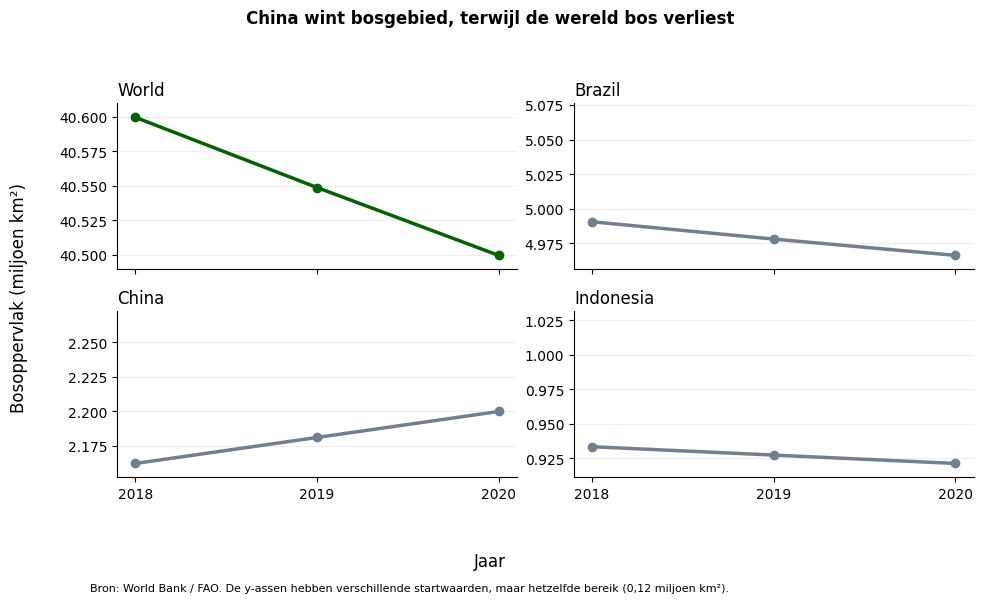

In [3]:
# AI-bron: prompt 2 (werkversie A, C en E).
landen = ["World", "Brazil", "China", "Indonesia"]
vergelijking = bos[bos["area_name"].isin(landen) & bos["year"].between(2018, 2020)]

fig, assen = plt.subplots(2, 2, figsize=(10, 6), sharex=True)

for land, ax in zip(landen, assen.flat):
    gegevens = vergelijking[vergelijking["area_name"] == land]
    oppervlakte = gegevens["forest_area"] / 1_000_000
    kleur = "darkgreen" if land == "World" else "slategray"
    ax.plot(gegevens["year"], oppervlakte, color=kleur, linewidth=2.5, marker="o")
    ax.set_title(land, loc="left")
    ax.set_xticks([2018, 2019, 2020])
    ax.set_ylim(oppervlakte.min() - 0.01, oppervlakte.min() + 0.11)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("China wint bosgebied, terwijl de wereld bos verliest", fontweight="bold")
fig.supylabel("Bosoppervlak (miljoen km²)")
fig.supxlabel("Jaar", y=0.045)
fig.text(0.1, 0.01, "Bron: World Bank / FAO. De y-assen hebben verschillende startwaarden, maar hetzelfde bereik (0,12 miljoen km²).", fontsize=8)
plt.tight_layout(rect=[0.03, 0.08, 1, 0.94])
plt.show()

### Onderbouwing C – zelf formuleren

- **Grafiekkeuze:** vier kleine lijngrafieken in één figuur; dezelfde jaren en hetzelfde verticale bereik in km²; verschillende startwaarden omdat de totale oppervlakken sterk uiteenlopen. Zo kun je de richting én absolute verandering vergelijken, maar niet de totale omvang op basis van de hoogte van de lijn.
- **Context:** China neemt toe (circa 37.592 km²), Brazilië en Indonesië nemen af, net als de wereld (circa 99.867 km² afname). Welke landen verdienen volgens jou nader onderzoek naar de oorzaken? De grafiek toont geen oorzaken.
- **Clutter:** directe landtitels in plaats van legenda; rustige hulplijnen; drie jaarmarkeringen; dezelfde opmaak en gelijke panelen (gestalt: overeenkomst en nabijheid).
- **Visuele focus:** groene wereldlijn als referentie; grijze landenlijnen; punten markeren de afzonderlijke jaren; titel wijst op het afwijkende patroon in China.

## D – Bosgebied in 2020

*Ruimte voor bijdrage medestudent.*

## E – Gemiddelde temperatuur per jaar (1995–2019)

Vraag: hoe ontwikkelt de gemiddelde temperatuur zich volgens de beschikbare stadsmetingen?

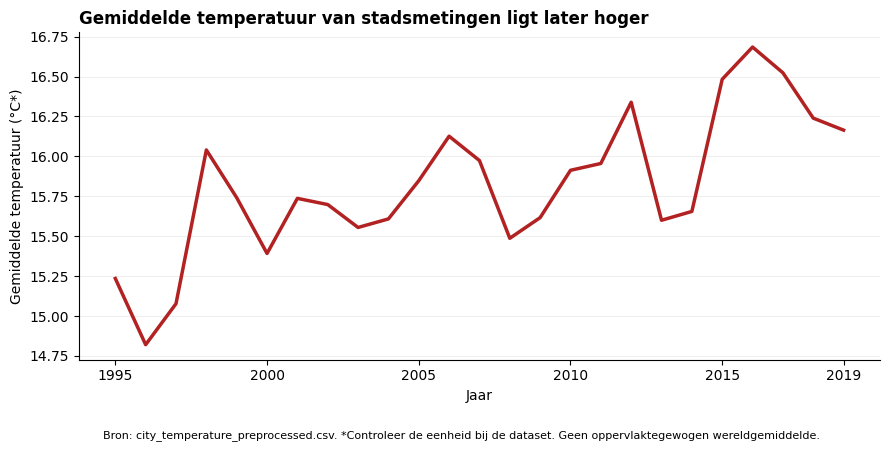

In [4]:
# AI-bron: prompt 2 (werkversie A, C en E).
temperatuur_periode = temperatuur[temperatuur["Year"].between(1995, 2019)]
jaargemiddelde = temperatuur_periode.groupby("Year")["AvgTemperature"].mean()

plt.figure(figsize=(9, 4.5))
plt.plot(jaargemiddelde.index, jaargemiddelde.values, color="firebrick", linewidth=2.5)
plt.title("Gemiddelde temperatuur van stadsmetingen ligt later hoger", loc="left", fontweight="bold")
plt.xlabel("Jaar")
plt.ylabel("Gemiddelde temperatuur (°C*)")
plt.xticks([1995, 2000, 2005, 2010, 2015, 2019])
plt.grid(axis="y", alpha=0.2)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.figtext(0.12, 0.015, "Bron: city_temperature_preprocessed.csv. *Controleer de eenheid bij de dataset. Geen oppervlaktegewogen wereldgemiddelde.", fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### Onderbouwing E – zelf formuleren

- **Grafiekkeuze:** lijngrafiek; jaargemiddelden vormen een tijdreeks; schommelingen blijven zichtbaar.
- **Context:** 1995 ≈ 15,23 en 2019 ≈ 16,16; 2016 is het hoogste gemiddelde in deze datasetperiode (≈ 16,69). De uitkomst is het gemiddelde van de beschikbare dagelijkse stadsmetingen, geen officieel oppervlaktegewogen wereldgemiddelde. Aantallen metingen verschillen per jaar. Controleer of °C de gedocumenteerde eenheid is. Welke aanvullende gegevens hebben VN-leiders nodig voordat ze conclusies trekken?
- **Clutter:** geen legenda voor één reeks; beperkte jaartallen; rustige horizontale hulplijnen; geen boven- en rechterrand.
- **Visuele focus:** rode lijn met extra dikte tegen een neutrale achtergrond; duidelijke titel en chronologische ordening (gestalt: continuïteit).

## F – Maandelijkse temperatuur Nederland

*Ruimte voor bijdrage medestudent.*

## Impact-evaluatie AI – nog zelf aanvullen

AI is ingezet voor uitleg over de opdracht, GitHub, het inladen van data en het voorbereiden van voorbeeldcode en ontwerpkeuzes voor A, C en E. De voorbeeldcode is uitgevoerd met de aangeleverde bestanden. De temperatuur-eenheid is niet gedocumenteerd in het CSV-bestand en moet nog bij de cursusbron worden geverifieerd. Het gemiddelde is niet geografisch gewogen.

**Vul zelf aan:** welke onderdelen heb je daadwerkelijk gebruikt, zelfstandig geschreven of aangepast? Welke positieve en negatieve effecten heb je ervaren? Hoe heb je de resultaten gecontroleerd en de beperkingen aangepakt? Controleer dat maximaal 50% van alle code in het gezamenlijke notebook letterlijk of vrijwel letterlijk uit bronnen komt.

## Referenties – nog aanvullen

- World Bank. (z.d.). *Forest area (sq. km)*. https://data.worldbank.org/indicator/AG.LND.FRST.K2?view=chart (voorbewerkte dataset `forest_area_cleaned.csv` via Brightspace).
- [Auteur/organisatie en jaar controleren]. *city_temperature_preprocessed.csv* [Dataset]. Brightspace, Visualisatie & Storytelling.
- ChatGPT (GPT-6.2, 2026). Prompt 1: Dataset inladen en filteren. [Voeg de echte gedeelde gesprekslink toe].
- ChatGPT (GPT-6.2, 2026). Prompt 2: Werkversie opdrachten A, C en E (met rubric). [Voeg de echte gedeelde gesprekslink toe].

Pas de promptnummering en titels aan op jullie echte prompts, voeg ook de overige gebruikte bronnen en prompts toe en volg de deelinstructies van de opleiding.